In [1]:
from superfv import HydroSolverOutput

import matplotlib.pyplot as plt


In [2]:
base_path = "/scratch/gpfs/jp7427/superfv/sinus-2d-profiling/"

def get_timing(name, N, cupy, nsteps):
    path = base_path
    if cupy:
        path += "cupy/"
    path += f"{name}/N_{N}"
    sim = HydroSolverOutput(path)

    if len(sim.step_history[2:]) != nsteps - 1:
        raise ValueError(f"Got unexpected number of steps: {len(sim.step_history[1:])}")

    nsteps = 0
    runtime = 0.0
    for s in sim.step_history[2:]:
        nsteps += 1
        runtime += s.timer["take_step"].cum_time

    update_rate = nsteps * sim.mesh.nx * sim.mesh.ny * sim.mesh.nz / runtime
    return update_rate

In [3]:
N_list = [32, 64, 128, 256, 512, 1024, 2048, 3072]
nsteps = 11

def plot_timing(ax, name, cupy, **kwargs):
    rate_list = []
    N_list_for_plotting = []
    for N in N_list:
        try:
            rate_list.append(get_timing(name, N, cupy, nsteps))
            N_list_for_plotting.append(N**2)
        except FileNotFoundError:
            pass
    ax.plot(N_list_for_plotting, rate_list, **kwargs)

In [4]:
plt.rcParams['font.size'] = 14

/home/jp7427/Desktop/superfv/superfv/mesh.py:266: UserWarning: Cupy is not available. Falling back to NumPy.
  warnings.warn("Cupy is not available. Falling back to NumPy.")


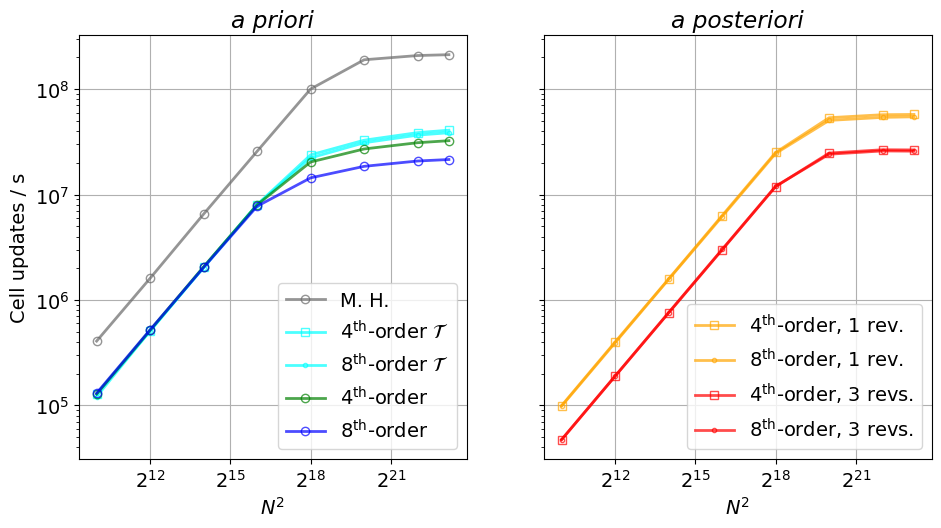

In [5]:
fig, axs = plt.subplots(1, 2, sharex=True, sharey=True, figsize=(11, 5.5))
axs[0].set_xscale("log", base=2)
axs[0].set_yscale("log")

common = dict(markersize=6, alpha=0.7, mfc="none", linewidth=2)

axs[0].set_title("a priori", style='italic')
plot_timing(axs[0], "MUSCL-Hancock", nsteps, label="M. H.", marker="o", color="dimgrey", **common)
plot_timing(axs[0], "ZS3t", nsteps, label=r"$4^{\mathrm{th}}$-order $\mathcal{T}$", marker="s", color="cyan", **common)
plot_timing(axs[0], "ZS7t", nsteps, label=r"$8^{\mathrm{th}}$-order $\mathcal{T}$", marker=".", color="cyan", **common)
plot_timing(axs[0], "ZS3", nsteps, label=r"$4^{\mathrm{th}}$-order", marker="o", color="green", **common)
plot_timing(axs[0], "ZS7", nsteps, label=r"$8^{\mathrm{th}}$-order", marker="o", color="blue", **common)

axs[1].set_title("a posteriori", style='italic')
plot_timing(axs[1], "MM3_1rev_rtol_0", nsteps, label=r"$4^{\mathrm{th}}$-order, 1 rev.", marker="s", color="orange", **common)
plot_timing(axs[1], "MM7_1rev_rtol_0", nsteps, label=r"$8^{\mathrm{th}}$-order, 1 rev.", marker=".", color="orange", **common)
plot_timing(axs[1], "MM3_3revs_rtol_0", nsteps, label=r"$4^{\mathrm{th}}$-order, 3 revs.", marker="s", color="red", **common)
plot_timing(axs[1], "MM7_3revs_rtol_0", nsteps, label=r"$8^{\mathrm{th}}$-order, 3 revs.", marker=".", color="red", **common)

axs[0].set_ylabel("Cell updates / s")
for ax in axs:
    ax.legend(loc="lower right")
    ax.grid()
    ax.set_xlabel(r"$N^2$")

fig.savefig("talk_roofline.pdf", bbox_inches="tight")